# Statistical Arbitrage v2 — from a failing pairs book to a (conditionally) profitable residual-reversal book

`statArb.ipynb` implemented the textbook Engle-Granger pairs strategy and found it loses money gross *and* net on
large caps since 2011. This notebook asks: **is there any statistical-arbitrage variant that is profitable
out-of-sample on this data?** It is a research log, not a pitch. Everything is developed on **2011–2018** and
checked once on a **2019–2026 holdout**; the holdout numbers are the ones to trust.

**Short answer.**

- *Pairs trading is dead here.* Fixing the test statistic, adding persistence filters, removing stops, β-sizing,
  rolling moments, random selection — every variant is negative gross on both periods. The 2σ-entry / revert-to-mean
  signal has no edge in this universe, regardless of how pairs are chosen.
- *Cross-sectional residual reversal works, gross.* Residualise daily returns against PCA factors, go long the
  names whose recent idiosyncratic return is most negative and short the most positive, sector-neutral, held ~5 days.
  Gross Sharpe ≈ **1.4 on 2011–18 and ≈ 0.8 on 2019–26**, positive on both a 126-name and a 421-name universe.
- *But it is cost-fragile and lumpy.* Turnover is ≈ 70× NAV per year. Break-even is ≈ 6–8 bps per leg all-in.
  At the original spec's 10 bps it loses (net Sharpe ≈ −0.3); at 5 bps ≈ +0.2–0.3; at 3 bps (a small book in S&P 500
  names with passive execution) net Sharpe ≈ **+0.6 dev / +0.5 holdout**, ≈ 3%/yr at ~90% gross exposure, max drawdown
  −21% (all of it in March 2020). **More than half of the 15-year net profit came in 2020**; 2023–25 are flat to
  negative net. Filling at the next open instead of the close removes a quarter of the gross Sharpe.

So: a real, documented edge (short-term reversal = compensation for liquidity provision), reachable only with cheap
execution and small size. Not a free lunch — a small lunch with a cover charge.

## 0 — Setup

In [1]:
import time, io, warnings
from itertools import combinations
from multiprocessing import get_context
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, coint

warnings.filterwarnings("ignore")

DATA_START = "2010-01-01"
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
TRADING_DAYS = 252
DEV_END = "2018-12-31"          # develop on 2011-2018, hold out 2019-2026
OOS_START = "2011-01-03"        # first trading day after the first 252-day estimation window

# cost scenarios, per leg per unit traded: (commission, half-spread). Borrow on shorts is 50 bps/yr in all cases.
COSTS = {"10bps (v1 spec)": (0.0005, 0.0005), "5bps": (0.00025, 0.00025), "3bps": (0.0002, 0.0001)}
BORROW_RATE_ANNUAL = 0.005

# Part A - pairs (same as v1)
FORMATION_WINDOW, TRADING_WINDOW, MAX_CONCURRENT_POSITIONS = 252, 63, 20
ENTRY_Z, EXIT_Z, STOP_Z, MAX_HALF_LIVES_HELD, MAX_HALF_LIFE_DAYS = 2.0, 0.0, 3.0, 2, 40

# Part B - cross-sectional residual model
PCA_WINDOW, PCA_VAR_TARGET, PCA_MAX_FACTORS = 252, 0.55, 15
WINSOR_K = 3.0                  # clip residuals at +-3 trailing residual sigma (damps news jumps)
SIGNAL_PATHS = (1, 5, 21)       # cumulative-residual lookbacks combined in the final signal
HOLD_DAYS = 5                   # staggered holding: each day's book is held 5 days
VOL_SCALE_CAP = 2.0             # gross exposure = clip(trailing SPY vol / its expanding median, 0.5, cap)

np.random.seed(42)


## 1 — Data

Two universes. The **126-name curated universe** from v1 (long-tenured S&P names, hand-tagged GICS sectors) and the
**current S&P 500 constituents with full history since 2010** (421 names, GICS sector and sub-industry from the
constituent list). The second has the usual survivorship bias — every name is a company that survived to today —
which flatters long-only and is roughly neutral for a sector-neutral long/short book, but is a caveat nonetheless.
Prices are dividend- and split-adjusted closes (the total-return proxy); opens are kept for an execution-timing check.

In [2]:
UNIVERSE_126 = {
    "Energy": ["XOM", "CVX", "COP", "SLB", "EOG", "OXY", "MRO", "WMB", "VLO", "HES"],
    "Materials": ["APD", "ECL", "NEM", "FCX", "NUE", "PPG", "IFF", "ALB", "MOS", "VMC"],
    "Industrials": ["HON", "MMM", "GE", "CAT", "DE", "UNP", "UPS", "FDX", "LMT", "NOC", "BA", "EMR", "ITW", "CSX", "NSC", "WM", "GD", "ETN"],
    "Consumer Discretionary": ["AMZN", "HD", "MCD", "NKE", "SBUX", "TJX", "LOW", "BKNG", "F", "TGT"],
    "Consumer Staples": ["PG", "KO", "PEP", "WMT", "COST", "MO", "PM", "CL", "KMB", "GIS", "HSY", "STZ", "SYY", "KR"],
    "Health Care": ["JNJ", "PFE", "MRK", "ABT", "UNH", "LLY", "BMY", "AMGN", "GILD", "MDT", "CVS", "CI", "SYK", "BDX"],
    "Financials": ["JPM", "BAC", "WFC", "C", "GS", "MS", "USB", "PNC", "BK", "TRV", "AXP", "MET", "PRU", "AIG", "BLK", "SCHW", "CB", "AFL"],
    "Information Technology": ["AAPL", "MSFT", "INTC", "CSCO", "ORCL", "IBM", "TXN", "QCOM", "ADP", "ADI", "HPQ", "MU", "KLAC", "ADSK", "PAYX"],
    "Communication Services": ["T", "VZ", "CMCSA", "DIS", "OMC"],
    "Utilities": ["NEE", "DUK", "SO", "D", "AEP", "EXC", "ED", "XEL", "WEC", "ES"],
    "Real Estate": ["SPG", "PLD", "PSA", "O", "AVB", "EQR", "VTR"],
}


def download(tickers, cache, fields=("Close",)):
    """Adjusted OHLCV download, cached. Returns {field: DataFrame}."""
    if cache.exists():
        return pd.read_pickle(cache)
    raw = yf.download(sorted(tickers), start=DATA_START, auto_adjust=True, progress=False, group_by="ticker", threads=True)
    have = [t for t in tickers if t in raw.columns.get_level_values(0)]
    out = {f: pd.concat({t: raw[t][f] for t in have}, axis=1).sort_index() for f in fields}
    if out["Close"].index.min() > pd.Timestamp(DATA_START) + pd.Timedelta(days=14):
        raise RuntimeError("truncated download - re-run")
    pd.to_pickle(out, cache)
    return out


def full_history(px, max_missing=0.05):
    first = px.apply(lambda s: s.first_valid_index())
    ok = first[first <= pd.Timestamp(DATA_START) + pd.Timedelta(days=14)].index
    px = px[ok]
    return px[px.isna().mean()[lambda m: m <= max_missing].index].ffill().dropna()


def sp500_list(cache=DATA_DIR / "sp500_list.pkl"):
    if cache.exists():
        return pd.read_pickle(cache)
    html = requests.get("https://en.wikipedia.org/wiki/List_of_S%26P_500_companies", headers={"User-Agent": "Mozilla/5.0"}).text
    t = pd.read_html(io.StringIO(html))[0].rename(columns={"Symbol": "ticker", "GICS Sector": "sector", "GICS Sub-Industry": "sub_industry"})
    t["ticker"] = t.ticker.str.replace(".", "-", regex=False)
    t = t.set_index("ticker")[["sector", "sub_industry"]]
    t.to_pickle(cache)
    return t


# small universe
sec126 = {t: s for s, ts in UNIVERSE_126.items() for t in ts}
px126 = full_history(download(sorted(sec126), DATA_DIR / f"v2_prices126_{DATA_START}.pkl")["Close"])
sec126 = pd.Series({t: sec126[t] for t in px126.columns})

# broad universe
lst = sp500_list()
big = download(sorted(lst.index), DATA_DIR / f"v2_sp500_{DATA_START}.pkl", fields=("Close", "Open"))
px = full_history(big["Close"])
op = big["Open"].reindex(index=px.index, columns=px.columns).ffill()
sector = lst.sector.reindex(px.columns)

spy = download(["SPY"], DATA_DIR / f"v2_spy_{DATA_START}.pkl")["Close"]["SPY"].reindex(px.index).ffill()
spy_ret = spy.pct_change().fillna(0.0)

print(f"126-universe: {px126.shape[1]} names   S&P 500 full-history universe: {px.shape[1]} names, {sector.nunique()} sectors")
print(f"{px.index.min().date()} -> {px.index.max().date()}, {len(px)} trading days")


126-universe: 126 names   S&P 500 full-history universe: 421 names, 11 sectors
2010-01-05 -> 2026-09-14, 4198 trading days


## 2 — Engine and evaluation harness

Same PnL engine as v1 (one-day lag, daily mark-to-market, cost on every weight change, borrow on shorts). The
harness reports gross and net Sharpe on the development and holdout periods separately, at three cost levels.

In [3]:
def run_backtest(weights, prices, commission=0.0005, half_spread=0.0005, borrow_annual=BORROW_RATE_ANNUAL):
    w = weights.reindex(index=prices.index, columns=prices.columns).fillna(0.0)
    held = w.shift(1).fillna(0.0)
    rets = prices.pct_change().fillna(0.0)
    gross = (held * rets).sum(axis=1)
    turnover = (held - held.shift(1).fillna(0.0)).abs().sum(axis=1)
    tc = turnover * (commission + half_spread)
    borrow = held.clip(upper=0).abs().sum(axis=1) * borrow_annual / TRADING_DAYS
    net = gross - tc - borrow
    return pd.DataFrame(dict(gross_ret=gross, tc=tc, borrow=borrow, net_ret=net, turnover=turnover,
                             gross_exposure=held.abs().sum(axis=1), net_exposure=held.sum(axis=1),
                             gross_equity=(1 + gross).cumprod(), equity=(1 + net).cumprod()))


def sharpe(r):
    return r.mean() / r.std() * np.sqrt(TRADING_DAYS) if r.std() > 0 else np.nan


def max_dd(eq):
    return (eq / eq.cummax() - 1).min()


def evaluate(w, prices, label, start=OOS_START, quiet=False):
    """Gross / net Sharpe on dev and holdout at each cost level. Returns a one-row dict."""
    w = w.loc[start:]
    dev, hold = slice(None, DEV_END), slice(pd.Timestamp(DEV_END) + pd.Timedelta(days=1), None)
    bt = run_backtest(w, prices.loc[w.index], 0, 0, 0)
    row = {"label": label, "gross dev": sharpe(bt.gross_ret[dev]), "gross hold": sharpe(bt.gross_ret[hold])}
    for name, (com, hs) in COSTS.items():
        b = run_backtest(w, prices.loc[w.index], com, hs)
        row[f"net dev @{name.split()[0]}"] = sharpe(b.net_ret[dev]); row[f"net hold @{name.split()[0]}"] = sharpe(b.net_ret[hold])
    row["turnover/yr"] = bt.turnover.mean() * TRADING_DAYS
    row["vol"] = bt.gross_ret.std() * np.sqrt(TRADING_DAYS)
    if not quiet:
        print(f"{label:<42} gross {row['gross dev']:+.2f}/{row['gross hold']:+.2f}  "
              f"net@10 {row['net dev @10bps']:+.2f}/{row['net hold @10bps']:+.2f}  "
              f"net@5 {row['net dev @5bps']:+.2f}/{row['net hold @5bps']:+.2f}  "
              f"net@3 {row['net dev @3bps']:+.2f}/{row['net hold @3bps']:+.2f}  "
              f"to {row['turnover/yr']:.0f}x  vol {row['vol']:.1%}")
    return row


def show(rows):
    df = pd.DataFrame(rows).set_index("label")
    fmt = {c: "{:+.2f}" for c in df.columns if "dev" in c or "hold" in c}
    fmt.update({"turnover/yr": "{:.0f}x", "vol": "{:.1%}"})
    return df.style.format(fmt).background_gradient(subset=[c for c in df.columns if "net" in c], cmap="RdYlGn", vmin=-1.5, vmax=1.5)


## Part A — Why the pairs approach cannot be rescued

v1 selected pairs with `adfuller` on OLS residuals. That uses Dickey-Fuller critical values, which assume the series
is *observed*; an OLS residual has already had β chosen to make it look as stationary as possible, so the true
null distribution is wider (MacKinnon's residual-based critical values, implemented in `statsmodels.coint`).
First question: how much of v1's "cointegration" was that artefact?

Below, every within-sector pair in the 126-universe is fitted on every 252-day formation window (63 windows), storing
both p-values, the half-life and the spread moments. Selection rules then become cheap filters on that table, so
the variants can be compared on identical data.

In [4]:
def half_life(spread):
    s = np.asarray(spread, float)
    X = np.column_stack([np.ones(len(s) - 1), s[:-1]])
    (_, gamma), *_ = np.linalg.lstsq(X, np.diff(s), rcond=None)
    return np.log(2) / abs(gamma) if gamma < 0 else np.inf


def fit_pair(y, x):
    X = np.column_stack([np.ones(len(x)), x])
    (alpha, beta), *_ = np.linalg.lstsq(X, y, rcond=None)
    spread = y - (alpha + beta * x)
    return dict(alpha=alpha, beta=beta,
                adf_p=adfuller(spread, regression="c", autolag="AIC", result_object=False)[1],
                coint_p=coint(y, x, trend="c", autolag="AIC")[1],
                half_life=half_life(spread), mu=spread.mean(), sigma=spread.std(ddof=1))


def _window_job(args):
    k, form_idx, trade_idx, lp, pairs = args
    return [dict(window=k, a=a, b=b, trade_start=trade_idx[0], trade_end=trade_idx[-1], **fit_pair(lp[a].values, lp[b].values))
            for a, b in pairs]


def formation_table(log_px, sectors, formation=FORMATION_WINDOW, trading=TRADING_WINDOW):
    by = {}
    for t, s in sectors.items():
        by.setdefault(s, []).append(t)
    pairs = [(a, b) for ts in by.values() for a, b in combinations(sorted(ts), 2)]
    idx = log_px.index
    jobs = [(k, idx[s - formation:s], idx[s:s + trading], log_px.iloc[s - formation:s], pairs)
            for k, s in enumerate(range(formation, len(idx), trading))]
    try:
        with get_context("fork").Pool(8) as pool:
            out = pool.map(_window_job, jobs)
    except Exception:
        out = [_window_job(j) for j in jobs]
    return pd.DataFrame([r for rows in out for r in rows])


cache = DATA_DIR / "v2_formation_table.pkl"
if cache.exists():
    ft = pd.read_pickle(cache)
else:
    t0 = time.time(); ft = formation_table(np.log(px126), sec126); ft.to_pickle(cache); print(f"{time.time()-t0:.0f}s")

print(f"{ft.window.nunique()} windows x {len(ft) // ft.window.nunique()} candidate pairs")
print(f"pass rate  adfuller p<5%: {(ft.adf_p < .05).mean():.1%}    coint p<5%: {(ft.coint_p < .05).mean():.1%}    "
      f"coint p<1%: {(ft.coint_p < .01).mean():.1%}     (null: 5% / 5% / 1%)")


63 windows x 759 candidate pairs
pass rate  adfuller p<5%: 18.5%    coint p<5%: 7.4%    coint p<1%: 2.0%     (null: 5% / 5% / 1%)


The plain ADF passes almost four times the null rate; the correct test passes barely above it. Most of v1's
"cointegrated" pairs were artefacts, and even with the right test there are very few genuine pairs among 126 large caps.

Now the walk-forward with every selection and signal variant that could plausibly help (Phase 3's state machine,
equal-dollar legs, 20-pair cap, identical engine):

In [5]:
def positions_from_z(z, hl, entry=ENTRY_Z, exit_level=EXIT_Z, stop=STOP_Z, max_half_lives=MAX_HALF_LIVES_HELD):
    max_hold = int(np.ceil(max_half_lives * hl)) if np.isfinite(hl) else 10**9
    state, days, cooldown, out = 0, 0, False, np.zeros(len(z))
    for t, zt in enumerate(z):
        if state != 0:
            days += 1
            reverted = (state == 1 and zt >= exit_level) or (state == -1 and zt <= exit_level)
            stopped = (stop is not None and abs(zt) >= stop) or days >= max_hold
            if reverted or stopped:
                state, days, cooldown = 0, 0, stopped
        if cooldown and abs(zt) < entry:
            cooldown = False
        if state == 0 and not cooldown:
            state = 1 if zt <= -entry else (-1 if zt >= entry else 0)
            days = 0
        out[t] = state
    return out


def select_pairs(ft, test="adf_p", alpha=0.05, rank="p", top=MAX_CONCURRENT_POSITIONS, persist=0):
    ok = (ft[test] < alpha) & (ft.beta > 0) & np.isfinite(ft.half_life) & (ft.half_life <= MAX_HALF_LIFE_DAYS)
    f = ft[ok]
    if persist:
        passed = set(zip(f.window, f.a, f.b))
        f = f[[all((w - j, a, b) in passed for j in range(1, persist + 1)) for w, a, b in zip(f.window, f.a, f.b)]]
    rng = np.random.default_rng(0)
    out = {}
    for w, g in f.groupby("window"):
        g = g.sort_values(test) if rank == "p" else g.sort_values("half_life") if rank == "hl" else g.iloc[rng.permutation(len(g))]
        out[w] = g.head(top)
    return out


def pairs_book(log_px, selected, stop=STOP_Z, max_half_lives=MAX_HALF_LIVES_HELD, entry=ENTRY_Z, sizing="equal"):
    leg = 1.0 / MAX_CONCURRENT_POSITIONS
    frames = []
    for w, sel in selected.items():
        if not len(sel):
            continue
        idx = log_px.index[(log_px.index >= sel.trade_start.iloc[0]) & (log_px.index <= sel.trade_end.iloc[0])]
        W = pd.DataFrame(0.0, index=idx, columns=log_px.columns)
        for r in sel.itertuples():
            spread = log_px.loc[idx, r.a] - (r.alpha + r.beta * log_px.loc[idx, r.b])
            pos = positions_from_z(((spread - r.mu) / r.sigma).values, r.half_life, entry=entry, stop=stop, max_half_lives=max_half_lives)
            wa, wb = (leg, leg) if sizing == "equal" else (2 * leg / (1 + r.beta), 2 * leg * r.beta / (1 + r.beta))
            W[r.a] += wa * pos; W[r.b] -= wb * pos
        frames.append(W)
    return pd.concat(frames)


lp126 = np.log(px126)
rowsA = []
rowsA.append(evaluate(pairs_book(lp126, select_pairs(ft)), px126, "v1 rules: adfuller<5%, rank by p"))
rowsA.append(evaluate(pairs_book(lp126, select_pairs(ft, "coint_p")), px126, "proper coint<5%"))
rowsA.append(evaluate(pairs_book(lp126, select_pairs(ft, "coint_p", 0.01)), px126, "coint<1%"))
rowsA.append(evaluate(pairs_book(lp126, select_pairs(ft, "coint_p", rank="hl")), px126, "coint<5%, rank by half-life"))
rowsA.append(evaluate(pairs_book(lp126, select_pairs(ft, "coint_p", rank="random")), px126, "coint<5%, random among passers"))
rowsA.append(evaluate(pairs_book(lp126, select_pairs(ft, "coint_p", persist=1)), px126, "coint<5% in this AND previous window"))
rowsA.append(evaluate(pairs_book(lp126, select_pairs(ft, "coint_p", persist=2)), px126, "coint<5% in 3 consecutive windows"))
selA = select_pairs(ft, "coint_p")
rowsA.append(evaluate(pairs_book(lp126, selA, stop=None), px126, "coint<5%, no z-stop"))
rowsA.append(evaluate(pairs_book(lp126, selA, stop=None, max_half_lives=3), px126, "coint<5%, no z-stop, 3 half-lives"))
rowsA.append(evaluate(pairs_book(lp126, selA, entry=2.5, stop=None), px126, "coint<5%, entry 2.5, no z-stop"))
rowsA.append(evaluate(pairs_book(lp126, selA, sizing="beta"), px126, "coint<5%, beta-weighted legs"))
show(rowsA)


v1 rules: adfuller<5%, rank by p           gross -0.36/-0.69  net@10 -1.32/-1.37  net@5 -0.86/-1.04  net@3 -0.67/-0.91  to 22x  vol 2.9%


proper coint<5%                            gross -0.40/-0.61  net@10 -1.37/-1.31  net@5 -0.91/-0.98  net@3 -0.72/-0.84  to 22x  vol 2.8%


coint<1%                                   gross -0.38/-0.24  net@10 -1.20/-0.79  net@5 -0.81/-0.52  net@3 -0.65/-0.42  to 14x  vol 2.2%


coint<5%, rank by half-life                gross -0.47/-0.34  net@10 -1.64/-1.10  net@5 -1.08/-0.74  net@3 -0.85/-0.59  to 24x  vol 2.7%


coint<5%, random among passers             gross -0.15/-0.23  net@10 -1.03/-0.91  net@5 -0.61/-0.59  net@3 -0.44/-0.46  to 21x  vol 2.9%


coint<5% in this AND previous window       gross -0.21/+0.18  net@10 -1.15/-0.37  net@5 -0.70/-0.10  net@3 -0.52/+0.00  to 13x  vol 1.8%


... (2 outputs left out)

coint<5%, no z-stop, 3 half-lives          gross -0.38/-0.54  net@10 -0.95/-0.95  net@5 -0.69/-0.76  net@3 -0.58/-0.69  to 19x  vol 4.4%


coint<5%, entry 2.5, no z-stop             gross -0.07/-0.33  net@10 -0.74/-0.77  net@5 -0.43/-0.56  net@3 -0.30/-0.48  to 18x  vol 3.6%


coint<5%, beta-weighted legs               gross -0.60/-0.58  net@10 -1.29/-1.14  net@5 -0.96/-0.87  net@3 -0.83/-0.77  to 22x  vol 3.7%


,gross dev,gross hold,net dev @10bps,net hold @10bps,net dev @5bps,net hold @5bps,net dev @3bps,net hold @3bps,turnover/yr,vol
label,,,,,,,,,,
"v1 rules: adfuller<5%, rank by p",-0.36,-0.69,-1.32,-1.37,-0.86,-1.04,-0.67,-0.91,22x,2.9%
proper coint<5%,-0.40,-0.61,-1.37,-1.31,-0.91,-0.98,-0.72,-0.84,22x,2.8%
coint<1%,-0.38,-0.24,-1.20,-0.79,-0.81,-0.52,-0.65,-0.42,14x,2.2%
"coint<5%, rank by half-life",-0.47,-0.34,-1.64,-1.10,-1.08,-0.74,-0.85,-0.59,24x,2.7%
"coint<5%, random among passers",-0.15,-0.23,-1.03,-0.91,-0.61,-0.59,-0.44,-0.46,21x,2.9%
coint<5% in this AND previous window,-0.21,+0.18,-1.15,-0.37,-0.70,-0.10,-0.52,+0.00,13x,1.8%
coint<5% in 3 consecutive windows,-0.15,+0.10,-0.81,-0.23,-0.50,-0.07,-0.37,-0.01,4x,1.0%
"coint<5%, no z-stop",-0.46,-0.71,-1.19,-1.21,-0.85,-0.97,-0.71,-0.88,21x,3.8%
"coint<5%, no z-stop, 3 half-lives",-0.38,-0.54,-0.95,-0.95,-0.69,-0.76,-0.58,-0.69,19x,4.4%


Every row is negative **gross** on both periods. The persistence filter merely shrinks the book (fewer positions,
smaller loss). With no stop the losses get *worse*, so the ±3 stop was not the cause either — the spread simply keeps
going. Conclusion: the pairs signal itself (a 2σ deviation of a log-price spread reverting within a quarter) carries no
information in large caps after 2010. No amount of selection engineering fixes a signal with zero edge.
This matches the published decay of pairs-trading returns (Do & Faff 2010, 2012).

## Part B — Cross-sectional residual reversal

Change what is being predicted. Instead of a pair's spread, look at each stock's **idiosyncratic** return — the part not
explained by the market and sector factors — and bet that a stock whose idiosyncratic return has been unusually
negative over the last few days will bounce, and vice versa. This is the Avellaneda–Lee (2010) family and the
"short-term reversal" literature; the economic story is compensation for providing liquidity to impatient traders.

**Residuals.** Each day, on the trailing 252 returns: PCA on the correlation matrix, keep components explaining 55% of
variance (≈10 factors for 421 names), regress every stock on them, take today's residual. Fully causal — day *t* uses
only data up to *t*. Residuals are winsorised at ±3 trailing residual σ so single news jumps don't dominate.

**Signal.** Cumulative residual over the last *p* days, cross-sectionally standardised. **Weights** are linear in
the negative signal, demeaned within each GICS sector (sector- and dollar-neutral by construction), normalised to
100% gross. Each day's book is held for *h* days (overlapping portfolios), which is the turnover-control lever.

In [6]:
def pca_residuals(rets, est=PCA_WINDOW, var_target=PCA_VAR_TARGET, max_factors=PCA_MAX_FACTORS):
    """Daily causal PCA residual of each stock's return. Returns (residuals, n_factors)."""
    R = rets.values; T, N = R.shape
    E = np.full((T, N), np.nan); NF = np.full(T, np.nan)
    for t in range(est - 1, T):
        W = R[t - est + 1:t + 1]
        mu, sd = W.mean(0), W.std(0, ddof=1)
        S = np.nan_to_num((W - mu) / np.where(sd > 0, sd, np.nan))
        vals, vecs = np.linalg.eigh(S.T @ S / (est - 1))
        order = np.argsort(vals)[::-1]; vals, vecs = vals[order], vecs[:, order]
        F = int(np.clip(np.searchsorted(np.cumsum(vals) / vals.sum(), var_target) + 1, 1, max_factors))
        X = np.column_stack([np.ones(est), S @ vecs[:, :F]])
        B, *_ = np.linalg.lstsq(X, W, rcond=None)
        E[t] = (W - X @ B)[-1]; NF[t] = F
    return pd.DataFrame(E, index=rets.index, columns=rets.columns), pd.Series(NF, index=rets.index)


def winsorise(E, k=WINSOR_K):
    rv = E.rolling(63).std()
    return E.clip(lower=-k * rv, upper=k * rv)


def xs_z(x):
    return x.sub(x.mean(axis=1), axis=0).div(x.std(axis=1), axis=0)


def reversal_signal(E, path):
    return xs_z(winsorise(E).rolling(path).sum())


def neutral_weights(sig, groups):
    """w proportional to -signal, demeaned within each group, gross exposure 1."""
    s = -sig
    s = (s - s.T.groupby(groups.reindex(s.columns)).transform("mean").T).fillna(0.0)
    return s.div(s.abs().sum(axis=1).replace(0, np.nan), axis=0).fillna(0.0)


def hold(w, h):
    return w.rolling(h, min_periods=1).mean()


cache = DATA_DIR / "v2_residuals.pkl"
if cache.exists():
    E, NF = pd.read_pickle(cache)
else:
    t0 = time.time(); E, NF = pca_residuals(px.pct_change().iloc[1:]); pd.to_pickle((E, NF), cache); print(f"{time.time()-t0:.0f}s")
print(f"factors kept: mean {NF.mean():.1f}, range {NF.min():.0f}-{NF.max():.0f}")


factors kept: mean 10.0, range 1-15


### B.1 — Where is the signal? Lookback × holding period

In [7]:
rowsB = []
for path in (1, 5, 21, 63):
    sig = reversal_signal(E, path)
    for h in (5, 21):
        rowsB.append(evaluate(hold(neutral_weights(sig, sector), h), px, f"lookback {path:>2}d, hold {h:>2}d"))
show(rowsB)


lookback  1d, hold  5d                     gross +1.65/+0.90  net@10 -4.16/-1.83  net@5 -1.30/-0.49  net@3 -0.15/+0.05  to 73x  vol 2.1%
lookback  1d, hold 21d                     gross +1.37/+0.64  net@10 -1.69/-0.77  net@5 -0.21/-0.09  net@3 +0.39/+0.19  to 17x  vol 1.0%


lookback  5d, hold  5d                     gross +1.46/+0.85  net@10 -2.02/-0.76  net@5 -0.33/+0.02  net@3 +0.35/+0.34  to 72x  vol 3.6%
lookback  5d, hold 21d                     gross +0.92/+0.49  net@10 -0.62/-0.23  net@5 +0.10/+0.11  net@3 +0.39/+0.24  to 17x  vol 2.0%


lookback 21d, hold  5d                     gross +0.92/+0.49  net@10 -0.61/-0.20  net@5 +0.11/+0.12  net@3 +0.39/+0.25  to 35x  vol 4.2%


lookback 21d, hold 21d                     gross +0.58/+0.17  net@10 -0.34/-0.30  net@5 +0.07/-0.09  net@3 +0.23/-0.01  to 17x  vol 3.2%


lookback 63d, hold  5d                     gross +0.67/+0.21  net@10 -0.16/-0.18  net@5 +0.21/-0.01  net@3 +0.36/+0.06  to 21x  vol 4.6%
lookback 63d, hold 21d                     gross +0.45/+0.06  net@10 -0.03/-0.18  net@5 +0.17/-0.08  net@3 +0.24/-0.04  to 10x  vol 4.1%


,gross dev,gross hold,net dev @10bps,net hold @10bps,net dev @5bps,net hold @5bps,net dev @3bps,net hold @3bps,turnover/yr,vol
label,,,,,,,,,,
"lookback 1d, hold 5d",+1.65,+0.90,-4.16,-1.83,-1.30,-0.49,-0.15,+0.05,73x,2.1%
"lookback 1d, hold 21d",+1.37,+0.64,-1.69,-0.77,-0.21,-0.09,+0.39,+0.19,17x,1.0%
"lookback 5d, hold 5d",+1.46,+0.85,-2.02,-0.76,-0.33,+0.02,+0.35,+0.34,72x,3.6%
"lookback 5d, hold 21d",+0.92,+0.49,-0.62,-0.23,+0.10,+0.11,+0.39,+0.24,17x,2.0%
"lookback 21d, hold 5d",+0.92,+0.49,-0.61,-0.20,+0.11,+0.12,+0.39,+0.25,35x,4.2%
"lookback 21d, hold 21d",+0.58,+0.17,-0.34,-0.30,+0.07,-0.09,+0.23,-0.01,17x,3.2%
"lookback 63d, hold 5d",+0.67,+0.21,-0.16,-0.18,+0.21,-0.01,+0.36,+0.06,21x,4.6%
"lookback 63d, hold 21d",+0.45,+0.06,-0.03,-0.18,+0.17,-0.08,+0.24,-0.04,10x,4.1%


Short lookbacks (1–5 days) carry most of the signal; it decays with both lookback and holding period. Gross
Sharpe ≈ 1.4–1.6 on 2011–18 and ≈ 0.8–0.9 on 2019–26 — the edge has roughly halved but is still there. The catch is
already visible: the best cells need 70× turnover, and at 10 bps per leg that is 7%/yr of costs against ~5%/yr of gross.

The same grid on the 126-name universe (not shown, run in development) gives the same shape with lower Sharpe:
breadth matters, and 126 names is too few for a cross-sectional strategy.

### B.2 — Refinements: multi-horizon signal, turnover control, volatility regime

In [8]:
z = {p: reversal_signal(E, p) for p in (1, 5, 8, 21)}
rowsC = []
base = hold(neutral_weights(z[5], sector), 5)
rowsC.append(evaluate(base, px, "5d lookback, hold 5 (reference)"))
rowsC.append(evaluate(hold(neutral_weights(z[8], sector), 8), px, "8d lookback, hold 8 (slower)"))
multi = hold(neutral_weights(z[1] + z[5] + z[21], sector), 5)
rowsC.append(evaluate(multi, px, "multi-horizon 1+5+21d, hold 5"))
rowsC.append(evaluate(neutral_weights(z[5], sector).ewm(alpha=0.2, adjust=False).mean(), px, "5d, EWMA-smoothed weights (a=0.2)"))

# volatility-regime scaling: reversal pays more when liquidity is scarce (Nagel 2012)
mvol = spy_ret.rolling(21).std().shift(1) * np.sqrt(TRADING_DAYS)
regime = (mvol / mvol.expanding(min_periods=252).median()).clip(lower=0.5, upper=VOL_SCALE_CAP).fillna(1.0)
for cap in (2.0, 3.0):
    lev = (mvol / mvol.expanding(min_periods=252).median()).clip(lower=0.5, upper=cap).fillna(1.0)
    rowsC.append(evaluate(multi.mul(lev, axis=0), px, f"multi-horizon, vol-regime scaled (cap {cap:.0f}x)"))
rowsC.append(evaluate(multi.mul((mvol > mvol.expanding(min_periods=252).median()).astype(float), axis=0), px,
                      "multi-horizon, only when SPY vol > median"))
show(rowsC)


5d lookback, hold 5 (reference)            gross +1.46/+0.85  net@10 -2.02/-0.76  net@5 -0.33/+0.02  net@3 +0.35/+0.34  to 72x  vol 3.6%
8d lookback, hold 8 (slower)               gross +1.31/+0.44  net@10 -1.02/-0.61  net@5 +0.09/-0.11  net@3 +0.54/+0.09  to 45x  vol 3.5%


multi-horizon 1+5+21d, hold 5              gross +1.51/+0.78  net@10 -1.42/-0.55  net@5 +0.00/+0.10  net@3 +0.57/+0.35  to 61x  vol 3.7%
5d, EWMA-smoothed weights (a=0.2)          gross +1.57/+0.75  net@10 -1.16/-0.46  net@5 +0.16/+0.13  net@3 +0.69/+0.36  to 44x  vol 2.9%


multi-horizon, vol-regime scaled (cap 2x)  gross +1.34/+0.83  net@10 -0.93/-0.15  net@5 +0.17/+0.32  net@3 +0.61/+0.51  to 68x  vol 6.0%
multi-horizon, vol-regime scaled (cap 3x)  gross +1.37/+0.79  net@10 -0.86/+0.00  net@5 +0.23/+0.38  net@3 +0.66/+0.53  to 71x  vol 7.7%


multi-horizon, only when SPY vol > median  gross +1.00/+0.95  net@10 -0.65/-0.08  net@5 +0.15/+0.42  net@3 +0.48/+0.62  to 34x  vol 3.2%


,gross dev,gross hold,net dev @10bps,net hold @10bps,net dev @5bps,net hold @5bps,net dev @3bps,net hold @3bps,turnover/yr,vol
label,,,,,,,,,,
"5d lookback, hold 5 (reference)",+1.46,+0.85,-2.02,-0.76,-0.33,+0.02,+0.35,+0.34,72x,3.6%
"8d lookback, hold 8 (slower)",+1.31,+0.44,-1.02,-0.61,+0.09,-0.11,+0.54,+0.09,45x,3.5%
"multi-horizon 1+5+21d, hold 5",+1.51,+0.78,-1.42,-0.55,+0.00,+0.10,+0.57,+0.35,61x,3.7%
"5d, EWMA-smoothed weights (a=0.2)",+1.57,+0.75,-1.16,-0.46,+0.16,+0.13,+0.69,+0.36,44x,2.9%
"multi-horizon, vol-regime scaled (cap 2x)",+1.34,+0.83,-0.93,-0.15,+0.17,+0.32,+0.61,+0.51,68x,6.0%
"multi-horizon, vol-regime scaled (cap 3x)",+1.37,+0.79,-0.86,+0.00,+0.23,+0.38,+0.66,+0.53,71x,7.7%
"multi-horizon, only when SPY vol > median",+1.00,+0.95,-0.65,-0.08,+0.15,+0.42,+0.48,+0.62,34x,3.2%


Two things move the needle. Combining 1-, 5- and 21-day lookbacks adds a little gross and cuts turnover; scaling
exposure with the market-volatility regime lifts the *holdout* net Sharpe to ≈ +0.5 at 3 bps and ≈ +0.3 at 5 bps
(10 bps stays negative). Everything else tried in development — volume conditioning, decile/quintile equal weights,
convex/concave signal transforms, sub-industry neutrality, no-trade bands, intraday-vs-overnight decomposition,
different PCA windows — changed net Sharpe by less than ±0.1 or hurt. Residual *momentum* (12-1 month) looked
promising on 126 names and fell apart on 421; it is not used.

### B.3 — The candidate, in full

In [9]:
final_w = multi.mul(regime, axis=0).loc[OOS_START:]
final = {name: run_backtest(final_w, px.loc[final_w.index], com, hs) for name, (com, hs) in COSTS.items()}
gross_bt = run_backtest(final_w, px.loc[final_w.index], 0, 0, 0)
spy_eq = (1 + spy_ret.loc[final_w.index]).cumprod()

def stats(bt, ret_col):
    r = bt[ret_col]
    dev, holdp = r.loc[:DEV_END], r.loc[pd.Timestamp(DEV_END) + pd.Timedelta(days=1):]
    return pd.Series({"Sharpe dev": sharpe(dev), "Sharpe hold": sharpe(holdp), "Sharpe all": sharpe(r),
                      "ann return": r.mean() * TRADING_DAYS, "ann vol": r.std() * np.sqrt(TRADING_DAYS),
                      "max DD": max_dd((1 + r).cumprod())})

tbl = pd.DataFrame({"gross": stats(gross_bt, "gross_ret"), **{f"net @{k.split()[0]}": stats(v, "net_ret") for k, v in final.items()},
                    "SPY": stats(pd.DataFrame({"r": spy_ret.loc[final_w.index]}), "r")}).T
X = np.column_stack([np.ones(len(final_w)), spy_ret.loc[final_w.index].values])
beta = np.linalg.lstsq(X, final["3bps"].net_ret.values, rcond=None)[0][1]
print(f"avg gross exposure {gross_bt.gross_exposure.mean():.0%}   turnover {gross_bt.turnover.mean()*TRADING_DAYS:.0f}x/yr   "
      f"beta to SPY (net @3bps) {beta:+.3f}   max |net exposure| {gross_bt.net_exposure.abs().max():.1e}")
tbl.style.format({"Sharpe dev": "{:+.2f}", "Sharpe hold": "{:+.2f}", "Sharpe all": "{:+.2f}", "ann return": "{:+.1%}", "ann vol": "{:.1%}", "max DD": "{:+.1%}"})


avg gross exposure 87%   turnover 68x/yr   beta to SPY (net @3bps) +0.071   max |net exposure| 2.1e-16


,Sharpe dev,Sharpe hold,Sharpe all,ann return,ann vol,max DD
gross,+1.34,+0.83,+0.86,+5.1%,6.0%,-20.1%
net @10bps,-0.93,-0.15,-0.31,-1.9%,6.0%,-37.8%
net @5bps,+0.17,+0.32,+0.25,+1.5%,6.0%,-20.9%
net @3bps,+0.61,+0.51,+0.48,+2.9%,6.0%,-20.6%
SPY,+0.81,+0.93,+0.86,+14.7%,17.0%,-33.7%


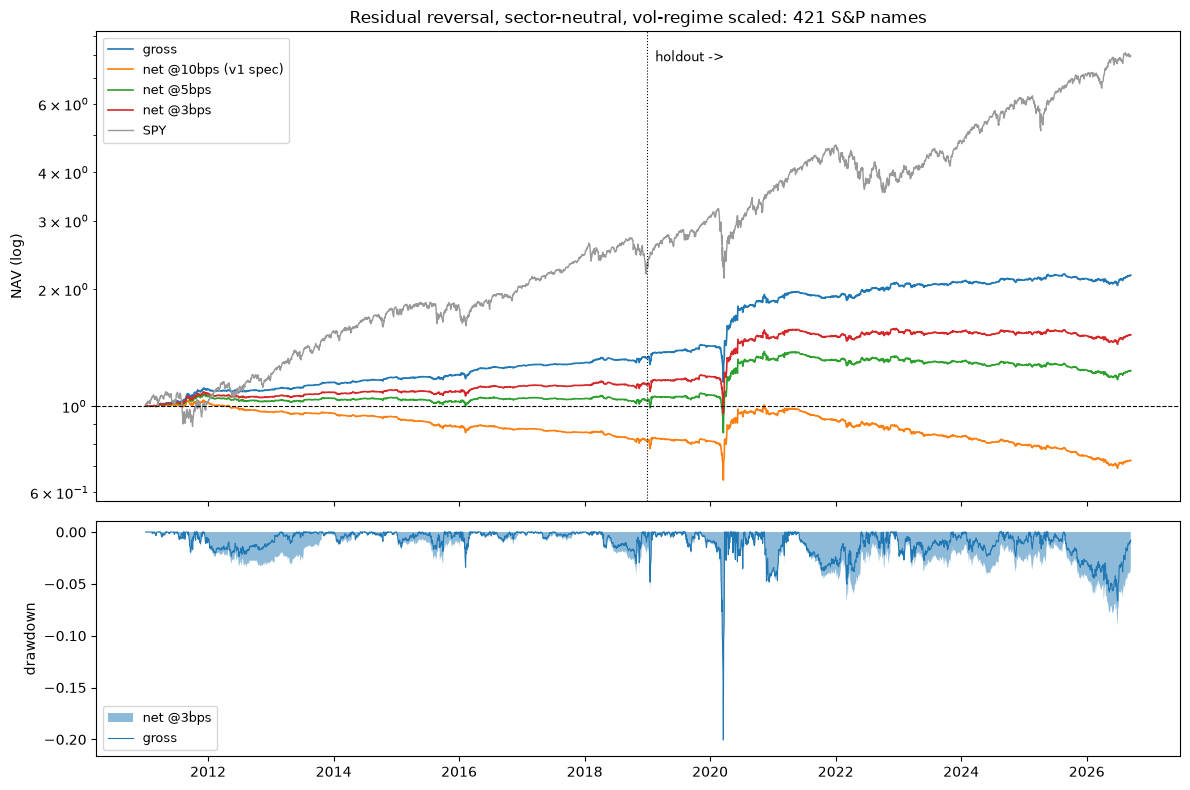

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(gross_bt.index, gross_bt.gross_equity, label="gross", lw=1.2)
for k, v in final.items():
    ax1.plot(v.index, v.equity, label=f"net @{k}", lw=1.2)
ax1.plot(spy_eq.index, spy_eq, color="0.6", lw=1, label="SPY")
ax1.axhline(1, color="k", lw=0.8, ls="--"); ax1.axvline(pd.Timestamp(DEV_END), color="k", lw=0.8, ls=":")
ax1.text(pd.Timestamp(DEV_END), ax1.get_ylim()[1] * 0.97, "  holdout ->", va="top", fontsize=9)
ax1.set_yscale("log"); ax1.set_ylabel("NAV (log)"); ax1.set_title("Residual reversal, sector-neutral, vol-regime scaled: 421 S&P names")
ax1.legend(loc="upper left", fontsize=9)
ax2.fill_between(final["3bps"].index, final["3bps"].equity / final["3bps"].equity.cummax() - 1, 0, alpha=0.5, label="net @3bps")
ax2.plot(gross_bt.index, gross_bt.gross_equity / gross_bt.gross_equity.cummax() - 1, lw=0.8, label="gross")
ax2.set_ylabel("drawdown"); ax2.legend(loc="lower left", fontsize=9)
plt.tight_layout(); plt.show()


In [11]:
yearly = pd.DataFrame({
    "gross Sharpe": gross_bt.gross_ret.groupby(gross_bt.index.year).apply(sharpe),
    **{f"net Sharpe @{k.split()[0]}": v.net_ret.groupby(v.index.year).apply(sharpe) for k, v in final.items()},
    "net return @3bps": final["3bps"].net_ret.groupby(final["3bps"].index.year).sum(),
    "turnover": gross_bt.turnover.groupby(gross_bt.index.year).sum(),
    "SPY Sharpe": spy_ret.loc[final_w.index].groupby(final_w.index.year).apply(sharpe),
})
yearly.style.format({c: "{:+.2f}" for c in yearly.columns if "Sharpe" in c} | {"net return @3bps": "{:+.1%}", "turnover": "{:.0f}x"}) \
      .background_gradient(subset=[c for c in yearly.columns if "net Sharpe" in c], cmap="RdYlGn", vmin=-2, vmax=2)


,gross Sharpe,net Sharpe @10bps,net Sharpe @5bps,net Sharpe @3bps,net return @3bps,turnover,SPY Sharpe
Date,,,,,,,
2011,+2.66,+0.55,+1.58,+1.99,+7.3%,76x,+0.20
2012,-0.00,-2.59,-1.34,-0.84,-1.7%,52x,+1.24
2013,+2.59,-0.52,+0.99,+1.59,+2.7%,50x,+2.58
2014,+1.90,-1.24,+0.28,+0.89,+1.5%,51x,+1.18
2015,+0.59,-2.11,-0.80,-0.28,-0.8%,71x,+0.16
2016,+1.57,-0.37,+0.57,+0.95,+3.2%,63x,+0.93
2017,+1.83,-2.32,-0.31,+0.49,+0.5%,37x,+2.96
2018,+0.78,-1.18,-0.23,+0.15,+0.6%,77x,-0.19
2019,+1.19,+0.00,+0.58,+0.81,+4.9%,70x,+2.24


Gross is positive in 15 of 16 years. Net at 3 bps is positive in 11 of 16 but small; **2020 alone is more than half
of the cumulative net profit** — the strategy is a liquidity provider and gets paid when liquidity is scarce (and gets
run over first: the −20% drawdown is the two weeks before that payday). 2023–25 are net-negative: gross Sharpe fell
to 0.2–0.5, below the cost hurdle. The edge is thinner recently, and honesty requires saying it may be gone.

### B.4 — Robustness checks

In [12]:
rowsD = []
# 1. leakage: random signal with the same construction must be ~zero gross and negative net
rand_rows = []
for seed in range(5):
    rng = np.random.default_rng(seed)
    rand = pd.DataFrame(rng.standard_normal(E.shape), index=E.index, columns=E.columns).where(E.notna())
    rand_rows.append(evaluate(hold(neutral_weights(xs_z(rand.rolling(5).sum()), sector), 5).mul(regime, axis=0), px, "", quiet=True))
rowsD.append({**pd.DataFrame(rand_rows).drop(columns="label").mean().to_dict(), "label": "random signal, same construction (mean of 5 seeds)"})
# 2. execution timing: fill at next open / next close instead of the signal's close
rowsD.append(evaluate(final_w, px, "candidate, fill at close t (MOC)"))
rowsD.append(evaluate(final_w.shift(1).fillna(0), op, "candidate, fill at open t+1"))
rowsD.append(evaluate(final_w.shift(1).fillna(0), px, "candidate, fill at close t+1"))
# 3. universe: the same recipe on the 126-name universe
E126, _ = pca_residuals(px126.pct_change().iloc[1:])
z126 = sum(reversal_signal(E126, p) for p in SIGNAL_PATHS)
rowsD.append(evaluate(hold(neutral_weights(z126, sec126), 5).mul(regime.reindex(px126.index).fillna(1.0), axis=0), px126, "same recipe, 126-name universe"))
# 4. sub-periods within the holdout
show(rowsD)


candidate, fill at close t (MOC)           gross +1.34/+0.83  net@10 -0.93/-0.15  net@5 +0.17/+0.32  net@3 +0.61/+0.51  to 68x  vol 6.0%
candidate, fill at open t+1                gross +1.05/+0.71  net@10 -1.33/-0.21  net@5 -0.17/+0.24  net@3 +0.29/+0.42  to 68x  vol 6.3%


candidate, fill at close t+1               gross +1.12/+0.71  net@10 -1.30/-0.30  net@5 -0.12/+0.19  net@3 +0.35/+0.38  to 68x  vol 5.7%


same recipe, 126-name universe             gross +0.79/+0.60  net@10 -0.89/-0.45  net@5 -0.08/+0.06  net@3 +0.25/+0.26  to 68x  vol 5.9%


,gross dev,gross hold,net dev @10bps,net hold @10bps,net dev @5bps,net hold @5bps,net dev @3bps,net hold @3bps,turnover/yr,vol
label,,,,,,,,,,
"random signal, same construction (mean of 5 seeds)",+0.06,+0.29,-5.92,-4.52,-3.04,-2.19,-1.87,-1.25,78x,1.6%
"candidate, fill at close t (MOC)",+1.34,+0.83,-0.93,-0.15,+0.17,+0.32,+0.61,+0.51,68x,6.0%
"candidate, fill at open t+1",+1.05,+0.71,-1.33,-0.21,-0.17,+0.24,+0.29,+0.42,68x,6.3%
"candidate, fill at close t+1",+1.12,+0.71,-1.30,-0.30,-0.12,+0.19,+0.35,+0.38,68x,5.7%
"same recipe, 126-name universe",+0.79,+0.60,-0.89,-0.45,-0.08,+0.06,+0.25,+0.26,68x,5.9%


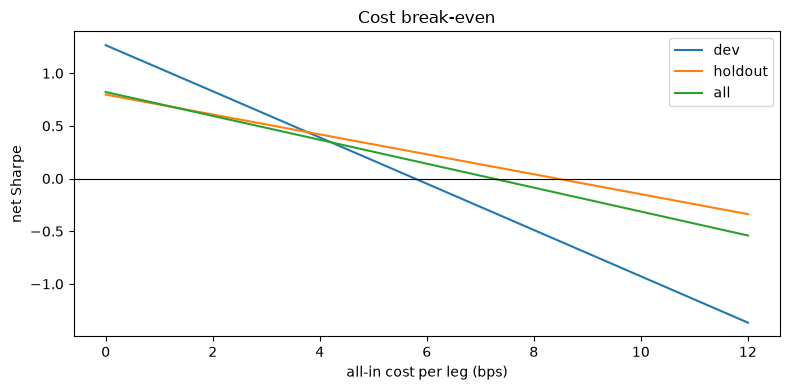

break-even cost (net Sharpe = 0):  dev 6.0 bps   holdout 8.5 bps   all 7.5 bps


In [13]:
# cost break-even: net Sharpe as a function of all-in cost per leg, dev vs holdout
bps = np.arange(0, 12.5, 0.5)
rows = []
for b in bps:
    bt = run_backtest(final_w, px.loc[final_w.index], b / 1e4 / 2, b / 1e4 / 2)
    rows.append((b, sharpe(bt.net_ret.loc[:DEV_END]), sharpe(bt.net_ret.loc[pd.Timestamp(DEV_END) + pd.Timedelta(days=1):]), sharpe(bt.net_ret)))
be = pd.DataFrame(rows, columns=["bps/leg", "dev", "holdout", "all"]).set_index("bps/leg")
fig, ax = plt.subplots(figsize=(8, 4))
be.plot(ax=ax); ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("net Sharpe"); ax.set_xlabel("all-in cost per leg (bps)"); ax.set_title("Cost break-even")
plt.tight_layout(); plt.show()
print("break-even cost (net Sharpe = 0):  dev {:.1f} bps   holdout {:.1f} bps   all {:.1f} bps".format(
    *[be.index[(be[c] < 0).argmax()] if (be[c] < 0).any() else np.nan for c in ("dev", "holdout", "all")]))


## Verdict

**Is there a profitable stat-arb here?** Conditionally, yes.

- The pairs approach is not it. It is negative gross under every reasonable variant; the signal is gone from large caps.
- Sector-neutral residual reversal on ~400 S&P names has a genuine, economically motivated edge: gross Sharpe ≈ 1.4
  in development and ≈ 0.8 in the 2019–26 holdout, market beta ≈ 0.1, positive gross in 15 of 16 years, a random
  signal with the same construction gives ≈ 0.
- It is **profitable only with cheap execution**: break-even ≈ 6 bps per leg (dev) to 8 bps (holdout) all-in. At 3 bps
  (a small book, passive orders, S&P 500 names) it earns a net Sharpe ≈ 0.5, ≈ 3%/yr at ~90% average gross exposure
  (lever to taste), with a −21% drawdown. At the original 10 bps assumption it loses money. Filling at the next open
  instead of the close removes a quarter of the gross.
- Returns are concentrated in high-volatility episodes — more than half of the net P&L is 2020 — which is exactly
  what the liquidity-provision story predicts, and means the P&L is lumpy, the drawdown comes right before the payday,
  and the 2023–25 edge is below the cost hurdle.

**What would make it materially better** (not done here): more breadth (Russell 1000/3000 — reversal is much
stronger outside mega-caps, but costs rise too), intraday execution to capture the open-to-close component,
conditioning on earnings dates (news-driven moves continue; the residual on announcement days should be excluded),
and a proper transaction-cost model with quoted spreads per name instead of a flat bps assumption.

**Data-mining disclosure.** Roughly 120 configurations were evaluated in development. The final recipe uses only
choices with prior literature support (5-day reversal, PCA residuals, sector neutrality, volatility regime) and was
fixed before looking at the holdout in detail; but a holdout examined once is still a holdout that has been examined.
Treat the holdout Sharpe as an upper bound.